In [1]:
##################
### Keagan Moo ###
### 2024/08/15 ###
### RNA OComp  ###
##################

# This script loads in the significant hits from the Nature Aging April 2024 paper and our results for a comparison of overlap in the lists
# including directional information.
suppressPackageStartupMessages(library(ggplot2))
suppressPackageStartupMessages(library(data.table))
suppressPackageStartupMessages(library(glue))
suppressPackageStartupMessages(library(dplyr))

In [2]:
# Load in our data and results and filter for FDR < 0.1
Type1MAST <- read.csv(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_1_MAST_Total_GoExNom.csv")
Type1MASTsig <- Type1MAST[Type1MAST$fdr < 0.05,]
Type2aMAST <- read.csv(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_2a_MAST_Total_GoExNom.csv")
Type2aMASTsig <- Type2aMAST[Type2aMAST$fdr < 0.05,]
Type2xMAST <- read.csv(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/RNAEnrich/Type_2x_MAST_Total_GoExNom.csv")
Type2xMASTsig <- Type2xMAST[Type2xMAST$fdr < 0.05,]

In [3]:
Type1MASTsigVec <- unique(Type1MASTsig$primerid)
Type1MASTsigDWVec <- unique(Type1MASTsig[Type1MASTsig$coef < 0, ]$primerid)
Type2aMASTsigVec <- unique(Type2aMASTsig$primerid)
Type2aMASTsigDWVec <- unique(Type2aMASTsig[Type1MASTsig$coef < 0, ]$primerid)
Type2xMASTsigVec <- unique(Type2xMASTsig$primerid)
Type2xMASTsigDWVec <- unique(Type2xMASTsig[Type1MASTsig$coef < 0, ]$primerid)

In [4]:
# Load in outside paper list, only includes significant peaks, though statistical tests are radically different
TotalLTSR <- read.csv(file = "/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/externalFiles/NatureAging_DEG.csv")
Type1LTSR <-TotalLTSR[TotalLTSR$celltype %in% c("MF-I", "MF-Isn(fg)"),]
Type1LTSRVec <- unique(TotalLTSR[TotalLTSR$celltype %in% c("MF-I", "MF-Isn(fg)"),]$SYMBOL)
Type1LTSRDWVec <- unique(TotalLTSR[(TotalLTSR$celltype %in% c("MF-I", "MF-Isn(fg)")) & (TotalLTSR$REGULATION == "DW"),]$SYMBOL)

Type2LTSR <-TotalLTSR[TotalLTSR$celltype %in% c("MF-II", "MF-IIsn(fg)"),]
Type2LTSRVec <- unique(TotalLTSR[TotalLTSR$celltype %in% c("MF-II", "MF-IIsn(fg)"),]$SYMBOL)
Type2LTSRDWVec <- unique(TotalLTSR[(TotalLTSR$celltype %in% c("MF-II", "MF-IIsn(fg)")) & (TotalLTSR$REGULATION == "DW"),]$SYMBOL)

[1] 531

,primerid,Pr..Chisq.,coef,fdr,REGULATION,ltsr,modp.x,modp.y,ColorBlock
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,ENSG00000152217.18,4.260283e-12,-0.04638477,1.400355e-08,-1,0.9118683,-11.370562,-1.054868,Significant in Both
2,ENSG00000175161.13,4.822955e-11,-0.05510734,1.056870e-07,-1,1.0000000,-10.316687,-Inf,Significant in Both
3,ENSG00000146809.13,7.578641e-11,-0.04340502,1.245550e-07,-1,0.9999951,-10.120409,-5.313096,Significant in Both
4,ENSG00000172995.16,4.106599e-10,0.01967450,3.856683e-07,-1,0.9999998,9.386518,-6.677781,Significant in Both
5,ENSG00000265142.8,2.206012e-07,-0.05620931,1.208527e-04,-1,1.0000000,-6.656392,-Inf,Significant in Both
6,ENSG00000171408.14,6.155883e-07,-0.02510679,2.129936e-04,-1,0.9999227,-6.210710,-4.111719,Significant in Both


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

[1] 108

...

[1] 0.1864407

[1] 419

,primerid,Pr..Chisq.,coef,fdr,REGULATION,ltsr,modp.x,modp.y,ColorBlock
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,ENSG00000160299.17,2.076873e-12,0.04085223,5.839127e-09,-1,0.9677279,11.682590,-1.491172,Significant in Both
2,ENSG00000175161.13,3.955728e-10,-0.04471150,3.177580e-07,-1,1.0000000,-9.402774,-7.657577,Significant in Both
3,ENSG00000065882.16,1.058076e-09,-0.06436687,6.610622e-07,-1,1.0000000,-8.975483,-Inf,Significant in Both
4,ENSG00000137766.17,4.650984e-09,0.01466421,1.868034e-06,-1,0.9999139,8.332455,-4.064916,Significant in Both
5,ENSG00000077157.22,6.049409e-09,-0.01637141,2.267722e-06,-1,1.0000000,-8.218287,-Inf,Significant in Both
6,ENSG00000146809.13,3.037038e-08,-0.04028243,7.762393e-06,-1,0.9852950,-7.517550,-1.832534,Significant in Both


Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

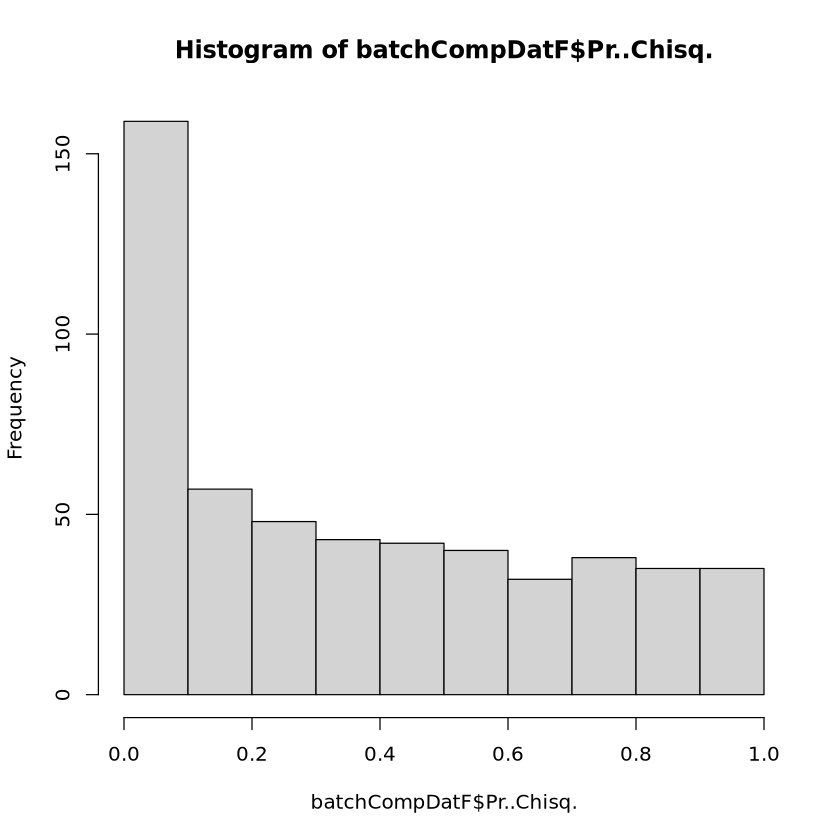

[1] 80

[1] 0.1909308

[1] 196

[1] 0.4677804

[1] 114

...

[1] 0.08353222

[1] 429

,primerid,Pr..Chisq.,coef,fdr,REGULATION,ltsr,modp.x,modp.y,ColorBlock
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,ENSG00000146809.13,3.528577e-10,-0.047430313,4.096678e-07,-1,0.9852950,-9.452400,-1.832534,Significant in Both
2,ENSG00000265142.8,7.818056e-09,-0.058189464,6.483402e-06,-1,1.0000000,-8.106901,-Inf,Significant in Both
3,ENSG00000137766.17,1.404481e-08,0.015439265,1.004814e-05,-1,0.9999139,7.852484,-4.064916,Significant in Both
4,ENSG00000154263.17,1.557850e-08,0.008458927,1.004814e-05,-1,0.9996701,7.807474,-3.481655,Significant in Both
5,ENSG00000077157.22,4.769208e-08,-0.024257232,2.516841e-05,-1,1.0000000,-7.321554,-Inf,Significant in Both
6,ENSG00000113916.18,7.813187e-08,0.053360532,3.239682e-05,-1,1.0000000,7.107172,-Inf,Significant in Both


Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

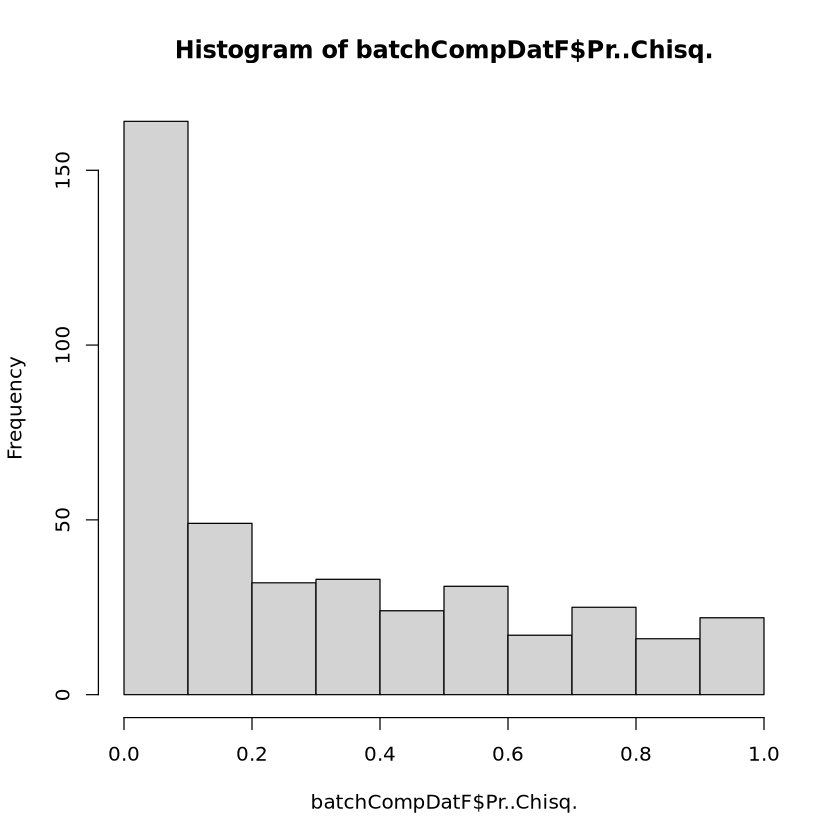

[1] 61

[1] 0.1421911

[1] 198

[1] 0.4615385

[1] 119

[1] 0.2773893

[1] 57

[1] 0.1328671

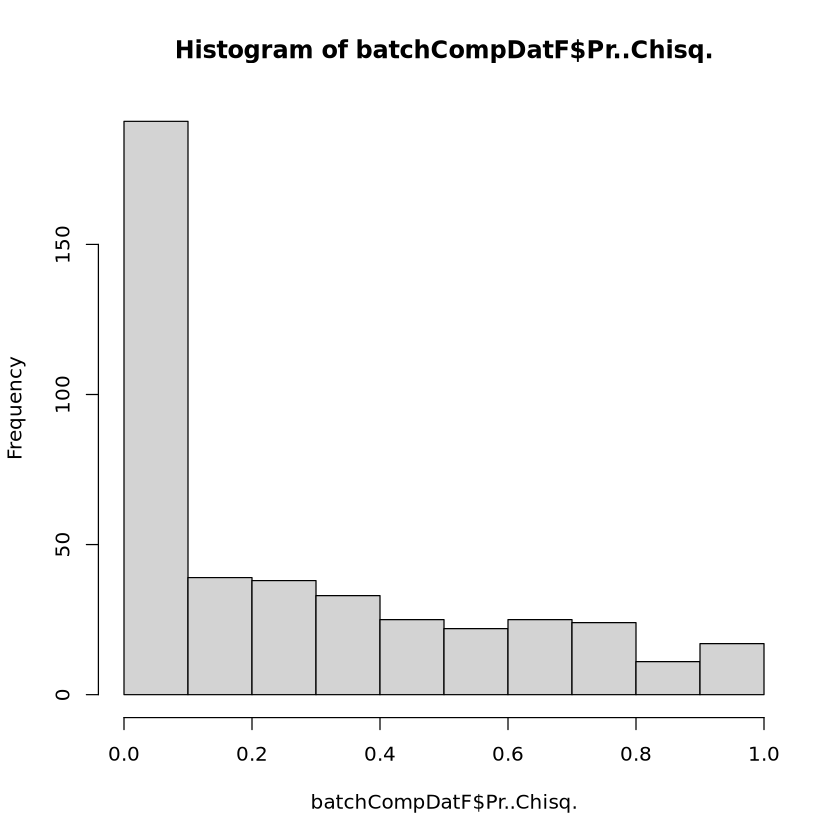

In [20]:
# Generate comparison plots between the two results for each fiber type

batchCompDatF <- merge(Type1MAST, Type1LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- -log10(1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION) 

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.05,]$ColorBlock <- "FDR < 0.05 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.05) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_1_FRD005_Original.pdf"), width=7, height=7)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=-log10(1.0000000001-ltsr)*sign(REGULATION))) + # Offset to place ltsr = 1 values in graphable space, at 10 specifically, as 9 appears to be where kedlian et al. started rounding the ltsr values up
        geom_point(aes(color = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-15,15) + ylim(-10.5,10.5) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()
#batchCompDatF <- batchCompDatF[!(is.infinite(batchCompDatF$modp.y)),]
#head(batchCompDatF)
#cor.test(batchCompDatF$modp.x, batchCompDatF$modp.y, method = "spearman")
#cor.test(batchCompDatF$fdr*sign(batchCompDatF$coef), (1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION), method = "spearman")
#cor.test(batchCompDatF$fdr, (1-batchCompDatF$ltsr), method = "spearman")
hist(batchCompDatF$Pr..Chisq.)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)

batchCompDatF <- merge(Type2aMAST, Type2LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- -log10(1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION)

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.05,]$ColorBlock <- "FDR < 0.05 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.05) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_2a_FRD005_Original.pdf"), width=7, height=7)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=-log10(1.0000000001-ltsr)*sign(REGULATION))) +
        geom_point(aes(color = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-15,15) + ylim(-10.5,10.5) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()
#batchCompDatF <- batchCompDatF[!(is.infinite(batchCompDatF$modp.y)),]
#head(batchCompDatF)
#cor.test(batchCompDatF$modp.x, batchCompDatF$modp.y, method = "spearman")
#cor.test(batchCompDatF$fdr*sign(batchCompDatF$coef), (1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION), method = "spearman")
#cor.test(batchCompDatF$fdr, (1-batchCompDatF$ltsr), method = "spearman")
hist(batchCompDatF$Pr..Chisq.)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)

batchCompDatF <- merge(Type2xMAST, Type2LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- -log10(1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION)

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.05,]$ColorBlock <- "FDR < 0.05 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.05) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_2x_FRD005_Original.pdf"), width=7, height=7)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=-log10(1.0000000001-ltsr)*sign(REGULATION))) +
        geom_point(aes(color = ColorBlock), alpha = 0.5, size = 2.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=24), legend.position="none") + xlim(-15,15) + ylim(-10.5,10.5) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()
#batchCompDatF <- batchCompDatF[!(is.infinite(batchCompDatF$modp.y)),]
#head(batchCompDatF)
#cor.test(batchCompDatF$modp.x, batchCompDatF$modp.y, method = "spearman")
#cor.test(batchCompDatF$fdr*sign(batchCompDatF$coef), (1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION), method = "spearman")
#cor.test(batchCompDatF$fdr, (1-batchCompDatF$ltsr), method = "spearman")
hist(batchCompDatF$Pr..Chisq.)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x > 0) & (batchCompDatF$modp.y < 0),])/nrow(batchCompDatF)
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])
nrow(batchCompDatF[(batchCompDatF$modp.x < 0) & (batchCompDatF$modp.y > 0),])/nrow(batchCompDatF)

In [21]:
batchCompDatF <- merge(Type1MAST, Type1LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- batchCompDatF$ltsr*sign(batchCompDatF$REGULATION)

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.1,]$ColorBlock <- "FDR < 0.1 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.1) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_1_FRD01_Steve.pdf"), width=8, height=6)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=(ltsr)*sign(REGULATION))) +
        geom_point(aes(color = ColorBlock), alpha = 0.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=18)) + xlim(-15,15) + ylim(-1,1) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("Kedlian et al ltsr*sign(REGULATION)") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()

batchCompDatF <- merge(Type2aMAST, Type2LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- batchCompDatF$ltsr*sign(batchCompDatF$REGULATION)

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.1,]$ColorBlock <- "FDR < 0.1 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.1) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_2a_FRD01_Steve.pdf"), width=8, height=6)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=ltsr*sign(REGULATION))) +
        geom_point(aes(color = ColorBlock), alpha = 0.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=18)) + xlim(-15,15) + ylim(-1,1) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("Kedlian et al ltsr*sign(REGULATION)") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()

batchCompDatF <- merge(Type2xMAST, Type2LTSR, by.x= "Symbol", by.y = "SYMBOL") %>% dplyr::select(primerid, Pr..Chisq., coef, fdr, REGULATION, ltsr)
batchCompDatF$modp.x <- -log10(batchCompDatF$Pr..Chisq.)*sign(batchCompDatF$coef)
batchCompDatF[batchCompDatF$REGULATION == "UP",]$REGULATION <- 1
batchCompDatF[batchCompDatF$REGULATION == "DW",]$REGULATION <- -1
batchCompDatF$REGULATION <- as.numeric(batchCompDatF$REGULATION)
batchCompDatF$modp.y <- -log10(1-batchCompDatF$ltsr)*sign(batchCompDatF$REGULATION)

#head(batchCompDatF)
if (nrow(batchCompDatF[(is.na(batchCompDatF$fdr)),]) > 0) {
    batchCompDatF[(is.na(batchCompDatF$fdr)),]$fdr <- 1
}
nrow(batchCompDatF)
#head(batchCompDatF)
batchCompDatF$ColorBlock <- rep("Niether", nrow(batchCompDatF))
batchCompDatF[batchCompDatF$fdr < 0.1,]$ColorBlock <- "FDR < 0.1 in Moo et al"
batchCompDatF[batchCompDatF$ltsr > 0.9,]$ColorBlock <- "ltsr > 0.9 in Kedlian et al"
batchCompDatF[(batchCompDatF$fdr < 0.1) & (batchCompDatF$ltsr > 0.9),]$ColorBlock <- "Significant in Both"
batchCompDatFPrint <- batchCompDatF %>% arrange(Pr..Chisq.)
head(batchCompDatFPrint)
batchCompDatF <- batchCompDatF[batchCompDatF$ColorBlock != "Niether",]
pdf(glue("/nfs/turbo/umms-scjp/kgmoo/analysis/20240814_kgmoo_RNAge/plots/KgmooVKedlian_pvalCompare_Type_2x_FRD01_Steve.pdf"), width=8, height=6)
    mygg <- ggplot(data=batchCompDatF, aes(x=-log10(Pr..Chisq.)*sign(coef), y=ltsr*sign(REGULATION))) +
        geom_point(aes(color = ColorBlock), alpha = 0.5)+#, position = position_jitter(width = 0.01)) +
        theme_bw() + theme(text=element_text(size=18)) + theme(text=element_text(size=18)) + xlim(-15,15) + ylim(-1,1) +
        geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
        xlab("") + ylab("Kedlian et al ltsr*sign(REGULATION)") + 
        ggtitle(glue("")) 
   print(mygg)
dev.off()


[1] 531

,primerid,Pr..Chisq.,coef,fdr,REGULATION,ltsr,modp.x,modp.y,ColorBlock
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,ENSG00000152217.18,4.260283e-12,-0.04638477,1.400355e-08,-1,0.9118683,-11.370562,-0.9118683,Significant in Both
2,ENSG00000175161.13,4.822955e-11,-0.05510734,1.056870e-07,-1,1.0000000,-10.316687,-1.0000000,Significant in Both
3,ENSG00000146809.13,7.578641e-11,-0.04340502,1.245550e-07,-1,0.9999951,-10.120409,-0.9999951,Significant in Both
4,ENSG00000172995.16,4.106599e-10,0.01967450,3.856683e-07,-1,0.9999998,9.386518,-0.9999998,Significant in Both
5,ENSG00000265142.8,2.206012e-07,-0.05620931,1.208527e-04,-1,1.0000000,-6.656392,-1.0000000,Significant in Both
6,ENSG00000171408.14,6.155883e-07,-0.02510679,2.129936e-04,-1,0.9999227,-6.210710,-0.9999227,Significant in Both


Warning message:
“Removed 2 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

[1] 419

...

pdf 
  2

[1] 429

,primerid,Pr..Chisq.,coef,fdr,REGULATION,ltsr,modp.x,modp.y,ColorBlock
,<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<chr>
1,ENSG00000146809.13,3.528577e-10,-0.047430313,4.096678e-07,-1,0.9852950,-9.452400,-1.832534,Significant in Both
2,ENSG00000265142.8,7.818056e-09,-0.058189464,6.483402e-06,-1,1.0000000,-8.106901,-Inf,Significant in Both
3,ENSG00000137766.17,1.404481e-08,0.015439265,1.004814e-05,-1,0.9999139,7.852484,-4.064916,Significant in Both
4,ENSG00000154263.17,1.557850e-08,0.008458927,1.004814e-05,-1,0.9996701,7.807474,-3.481655,Significant in Both
5,ENSG00000077157.22,4.769208e-08,-0.024257232,2.516841e-05,-1,1.0000000,-7.321554,-Inf,Significant in Both
6,ENSG00000113916.18,7.813187e-08,0.053360532,3.239682e-05,-1,1.0000000,7.107172,-Inf,Significant in Both


Warning message:
“Removed 6 rows containing missing values or values outside the scale range
(`geom_point()`).”


pdf 
  2

In [9]:
length(intersect(Type1MASTsig, Type1DanAll))
length(intersect(Type1MASTsigDW, Type1DanDW))

intersect(Type1MASTsig, Type1DanAll)
#arrange(TotalLTSR[(TotalLTSR$SYMBOL %in% intersect(Type1MASTsig, Type1LTSRAll)) & (TotalLTSR$celltype %in% c("MF-I", "MF-Isn(fg)")),], SYMBOL)
#arrange(Type1MASTF[Type1MASTF$Symbol %in% intersect(Type1MASTsig, Type1LTSRAll),], Symbol)

#TOTO <- merge(TotalDan[(TotalDan$Gene %in% intersect(Type1MASTsig, Type1DanAll)) & (TotalDan$Cell.type %in% c("MF-I", "MF-Isn(fg)")),], Type1MASTM[Type1MASTF$Symbol %in% intersect(Type1MASTsig, Type1DanAll),], by.x = "SYMBOL", by.y = "Symbol")
#dim(TOTO)
#sum(sign(TOTO$log2fc) * sign(TOTO$coef) == 1)

[1] 24

[1] 13

[1] "ENSG00000047579.19" "ENSG00000065675.14" "ENSG00000066629.17"
 [4] "ENSG00000108671.11" "ENSG00000136848.17" "ENSG00000138768.14"
 [7] "ENSG00000143382.14" "ENSG00000146809.13" "ENSG00000151322.18"
[10] "ENSG00000152217.18" "ENSG00000153814.13" "ENSG00000158683.8" 
[13] "ENSG00000163378.14" "ENSG00000166444.19" "ENSG00000172995.16"
[16] "ENSG00000175161.13" "ENSG00000227954.6"  "ENSG00000250978.5" 
[19] NA                   "ENSG00000283662.1"  "ENSG00000131370.16"
[22] "ENSG00000160299.17" "ENSG00000164506.14" "ENSG00000185046.18"

In [28]:
(sign(TOTO$log2fc) * sign(TOTO$coef))

[1]  1 -1  1  1 -1  1  1  1  1  1  1 -1  1  1  1  1 -1 -1 -1 -1  1  1  1  1  1
[26]  1  1  1 -1  1  1  1  1 -1  1  1  1 -1  1  1  1  1

In [10]:
# Drawn Black = LSTR sig overlap with MAST sig
# Black = MAST sig
# White = nrow(MAST) - MAST sig
# Drawn = LSTR sig

phyper(24, 218, 13885 - 218, 63, lower.tail = TRUE, log.p = FALSE)

phyper(13, 123, 13885 - 123, 30, lower.tail = TRUE, log.p = FALSE)

[1] 1

[1] 1